# EARTHSC 5201: Homework 3

## Rory Levinson

### Question 1

####  Last year there was an earthquake in Oak Hill, OH (https://earthquake.usgs.gov/earthquakes/eventpage/se60597816/executive). We will assume that the depth of the earthquake is the published depth of 25.9 km. The following nearby stations have nice P wave arrivals: N4.Q51A, N4.Q52A, OH.CHWO, OH.CPOH, OH.DSFO, and OH.SSF2.

### A.

#### Retrieve the vertical component waveforms for each of these stations and determine the P wave by manually picking it (for this, you can zoom into the time of the P wave arrival and get it roughly to the nearest tenth of a second).

In [3]:
!mamba install obspy

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, obspy
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.768 seconds
All requested packages already installed.


In [9]:
from obspy import UTCDateTime
from obspy.clients.fdsn import Client
client_events = Client("https://earthquake.usgs.gov", _discover_services=False)

event1 = client_events.get_events(
    starttime=UTCDateTime("2025-02-03T21:04:52.85"),
    endtime=UTCDateTime("2025-02-03T21:05:52.85"),
    minmagnitude=3.0,
    maxmagnitude=3.2,
)
print(event1)

event = event1[0]
origin = event.preferred_origin() or event.origins[0]
magnitude = event.preferred_magnitude() or event.magnitudes[0]

print(f"{origin.time}  M{magnitude.mag:.1f}  "
      f"lat={origin.latitude:.2f}, lon={origin.longitude:.2f}, depth={origin.depth/1000:.1f} km")

1 Event(s) in Catalog:
2025-02-03T21:04:52.850000Z | +38.920,  -82.581 | 3.1  md | manual
2025-02-03T21:04:52.850000Z  M3.1  lat=38.92, lon=-82.58, depth=25.9 km


##### N4.Q51A

In [28]:
client = Client("https://service.earthscope.org", _discover_services=False)

t0 = origin.time
st_1 = client.get_waveforms(
    network="N4", station="Q51A", location="00", channel="HHZ",
    starttime=t0, endtime=t0 + 3600,
)

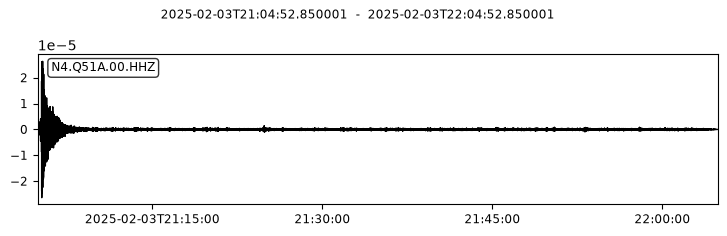

In [43]:
inv_resp_1 = client.get_stations(
    network="N4", station="Q51A", channel="HHZ", location="00",
    starttime=t0, endtime=t0 + 3600,
    level="response",
)

st_1_corrected = st_1.copy()
st_1_corrected.remove_response(inventory=inv_resp_1, output="VEL")

st_1_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

st_1_corrected.plot();

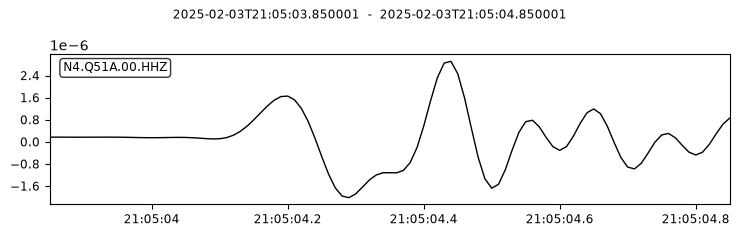

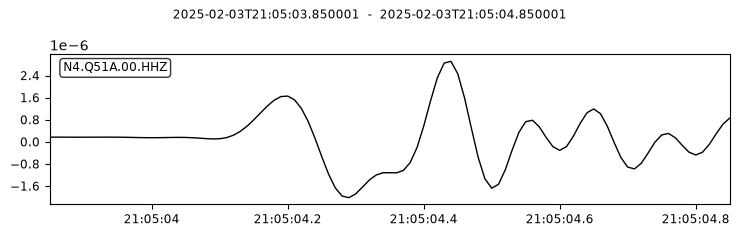

In [81]:
EQ = UTCDateTime("2025-02-03T21:04:52.85")

st_1_zoom = st_1_corrected.copy()
st_1_zoom.trim(
    starttime=EQ + 11,
    endtime=EQ + 12
)

st_1_zoom.plot()

#### The P-wave arrival time for this station is about 21:05:04.1 on 2025-02-03.

##### N4.Q52A

In [45]:
client = Client("https://service.earthscope.org", _discover_services=False)

t0 = origin.time
st_2 = client.get_waveforms(
    network="N4", station="Q52A", location="00", channel="HHZ",
    starttime=t0, endtime=t0 + 3600,
)

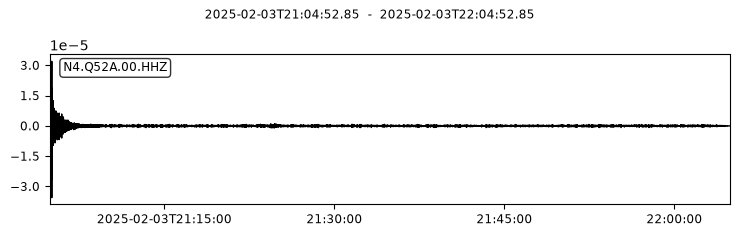

In [49]:
inv_resp_2 = client.get_stations(
    network="N4", station="Q52A", channel="HHZ", location="00",
    starttime=t0, endtime=t0 + 3600,
    level="response",
)

st_2_corrected = st_2.copy()
st_2_corrected.remove_response(inventory=inv_resp_2, output="VEL")

st_2_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

st_2_corrected.plot();

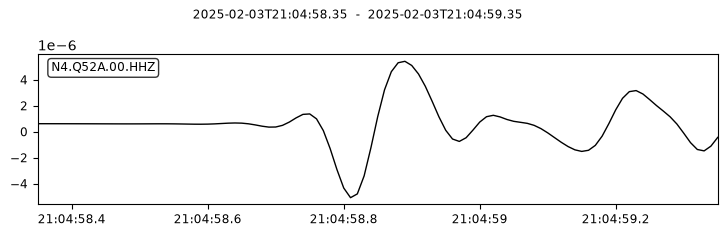

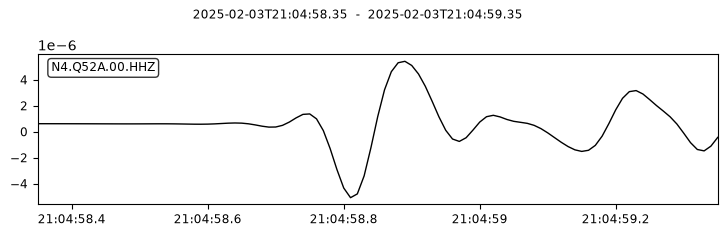

In [87]:
st_2_zoom = st_2_corrected.copy()
st_2_zoom.trim(
    starttime=EQ + 5.5,
    endtime=EQ + 6.5
)

st_2_zoom.plot()

#### The P-wave arrival time for this station is about 21:04.58.7 on 2025-02-03.

##### OH.CHWO

In [30]:
client = Client("https://service.earthscope.org", _discover_services=False)

t0 = origin.time
st_3 = client.get_waveforms(
    network="OH", station="CHWO", location="", channel="HHZ",
    starttime=t0, endtime=t0 + 3600,
)

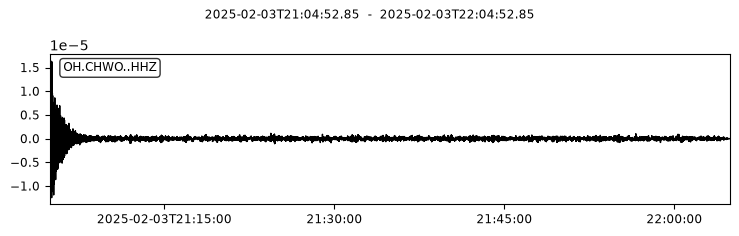

In [50]:
inv_resp_3 = client.get_stations(
    network="OH", station="CHWO", channel="HHZ", location="",
    starttime=t0, endtime=t0 + 3600,
    level="response",
)

st_3_corrected = st_3.copy()
st_3_corrected.remove_response(inventory=inv_resp_3, output="VEL")

st_3_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

st_3_corrected.plot();

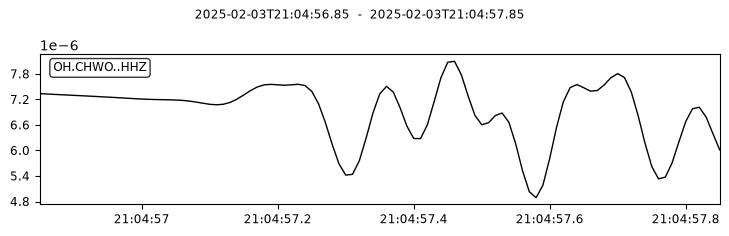

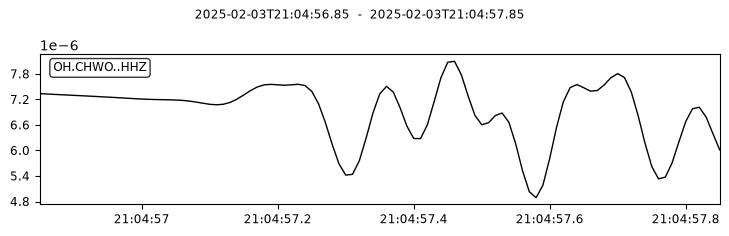

In [91]:
st_3_zoom = st_3_corrected.copy()
st_3_zoom.trim(
    starttime=EQ + 4,
    endtime=EQ + 5
)

st_3_zoom.plot()

#### The P-wave arrival time for this station is about 21:04:57.1 on 2025-02-03.

##### OH.CPOH

In [31]:
client = Client("https://service.earthscope.org", _discover_services=False)

t0 = origin.time
st_4 = client.get_waveforms(
    network="OH", station="CPOH", location="", channel="HHZ",
    starttime=t0, endtime=t0 + 3600,
)

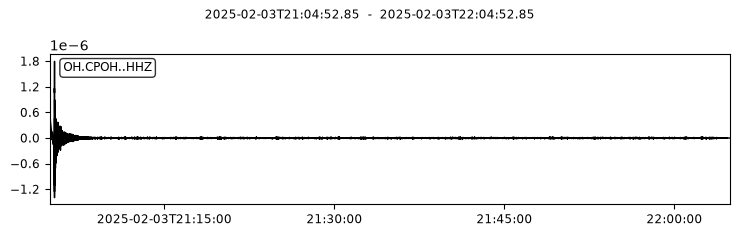

In [53]:
inv_resp_4 = client.get_stations(
    network="OH", station="CPOH", channel="HHZ", location="",
    starttime=t0, endtime=t0 + 3600,
    level="response",
)

st_4_corrected = st_4.copy()
st_4_corrected.remove_response(inventory=inv_resp_4, output="VEL")

st_4_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

st_4_corrected.plot();

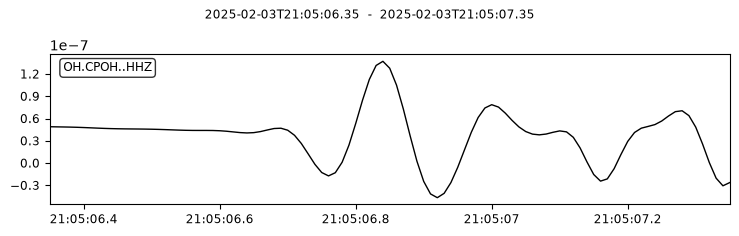

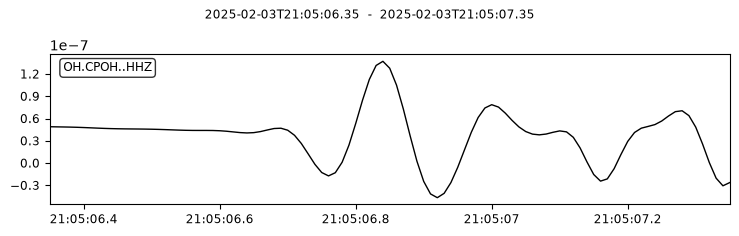

In [96]:
st_4_zoom = st_4_corrected.copy()
st_4_zoom.trim(
    starttime=EQ + 13.5,
    endtime=EQ + 14.5
)

st_4_zoom.plot()

#### The P-wave arrival time for this station is about 21:05:06.7 on 2025-02-03.

##### OH.DSFO

In [35]:
client = Client("https://service.earthscope.org", _discover_services=False)

t0 = origin.time
st_5 = client.get_waveforms(
    network="OH", station="DSFO", location="10", channel="HHZ",
    starttime=t0, endtime=t0 + 3600,
)

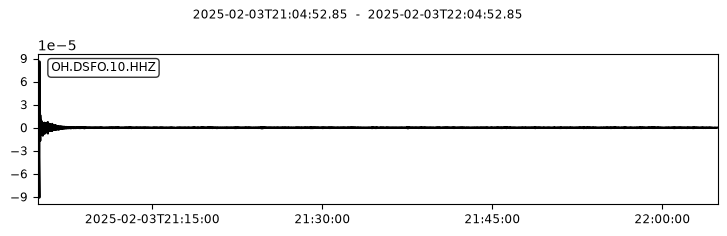

In [55]:
inv_resp_5 = client.get_stations(
    network="OH", station="DSFO", channel="HHZ", location="10",
    starttime=t0, endtime=t0 + 3600,
    level="response",
)

st_5_corrected = st_5.copy()
st_5_corrected.remove_response(inventory=inv_resp_5, output="VEL")

st_5_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

st_5_corrected.plot();

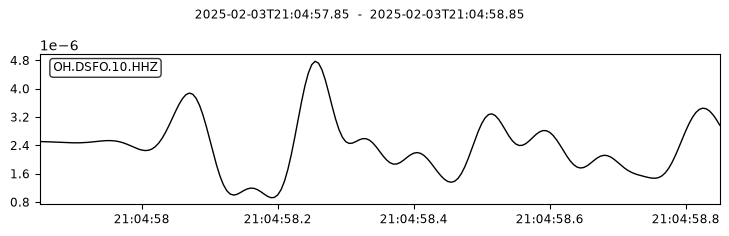

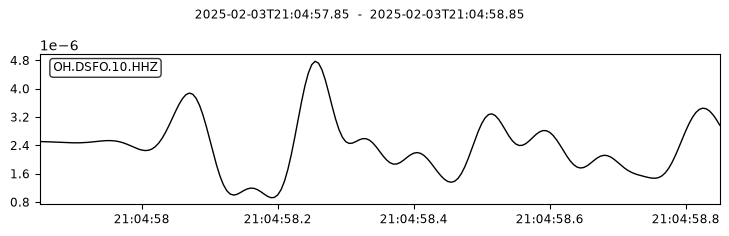

In [103]:
st_5_zoom = st_5_corrected.copy()
st_5_zoom.trim(
    starttime=EQ + 5,
    endtime=EQ + 6
)

st_5_zoom.plot()

#### The P-wave arrival time for this station is about 21:04:57.9 on 2025-02-03.

##### OH.SSF2

In [57]:
client = Client("https://service.earthscope.org", _discover_services=False)

t0 = origin.time
st_6 = client.get_waveforms(
    network="OH", station="SSF2", location="", channel="HHZ",
    starttime=t0, endtime=t0 + 3600,
)

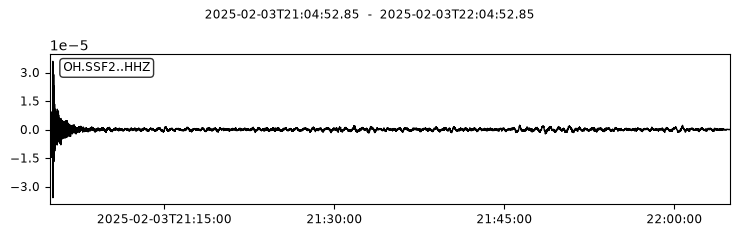

In [58]:
inv_resp_6 = client.get_stations(
    network="OH", station="SSF2", channel="HHZ", location="",
    starttime=t0, endtime=t0 + 3600,
    level="response",
)

st_6_corrected = st_6.copy()
st_6_corrected.remove_response(inventory=inv_resp_6, output="VEL")

st_6_corrected.filter("bandpass", freqmin=0.02, freqmax=9.99, corners=4, zerophase=True)

st_6_corrected.plot();

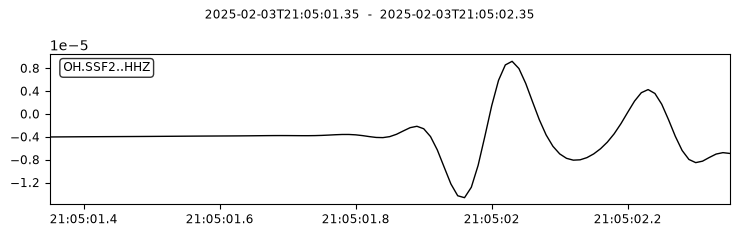

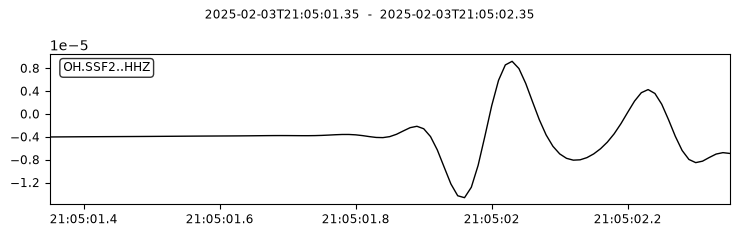

In [108]:
st_6_zoom = st_6_corrected.copy()
st_6_zoom.trim(
    starttime=EQ + 8.5,
    endtime=EQ + 9.5
)

st_6_zoom.plot()

#### The P-wave arrival time for this station is about 21:05:01.9 on 2025-02-03.

### B.

#### Given the published location of the earthquake of 38.920 degrees N and 82.581 degrees W, find a single P-wave velocity that best fits the data. To compute hypocentral distances, the function geopy.distance.distance works well to get epicentral distance, and then you can do sqrt(epidist^2+depth^2)=hypodist. Usage for geopy.distance.distance is:
#### coord1 = (lat1,lon1)
#### coord2 = (lat2,lon2)
#### epidist = geopy.distance.distance(coord1,coord2).km

In [110]:
stations = [("N4", "Q51A"), ("N4", "Q52A"), ("OH", "CHWO"), ("OH", "CPOH"), ("OH", "DSFO"), ("OH", "SSF2")]

for network, station in stations:

    inv = client.get_stations(
        network=network,
        station=station,
        channel="HHZ",
        starttime=origin.time,
        endtime=origin.time + 3600,
        level="station"
    )

    st = inv[0][0]

    print(
        network,
        station,
        "lat =", st.latitude,
        "lon =", st.longitude,
    )

N4 Q51A lat = 39.026 lon = -83.3456
N4 Q52A lat = 38.9622 lon = -82.2669
OH CHWO lat = 38.93602 lon = -82.526105
OH CPOH lat = 38.8401 lon = -83.5776
OH DSFO lat = 38.690952 lon = -82.616898
OH SSF2 lat = 38.6886 lon = -83.1276


In [123]:
import geopy.distance

coord1 = (39.026,-83.3456)
coord2 = (38.920,-82.581)
epidist_1 = geopy.distance.distance(coord1,coord2).km

coord1 = (38.9622, -82.2669)
coord2 = (38.920,-82.581)
epidist_2 = geopy.distance.distance(coord1,coord2).km

coord1 = (38.93602, -82.526105)
coord2 = (38.920,-82.581)
epidist_3 = geopy.distance.distance(coord1,coord2).km

coord1 = (38.8401, -83.5776)
coord2 = (38.920,-82.581)
epidist_4 = geopy.distance.distance(coord1,coord2).km

coord1 = (38.690952, -82.616898)
coord2 = (38.920,-82.581)
epidist_5 = geopy.distance.distance(coord1,coord2).km

coord1 = (38.6886, -83.1276)
coord2 = (38.920,-82.581)
epidist_6 = geopy.distance.distance(coord1,coord2).km

print(f"{epidist_1} km")
print(f"{epidist_2} km")
print(f"{epidist_3} km")
print(f"{epidist_4} km")
print(f"{epidist_5} km")
print(f"{epidist_6} km")

67.29633179637696 km
27.631916918191354 km
5.081545178709734 km
86.93070491630095 km
25.617509172491122 km
53.98359308873148 km


In [128]:
import math

hypodist_1 = math.sqrt(epidist_1**2+25.9**2)

hypodist_2 = math.sqrt(epidist_2**2+25.9**2)

hypodist_3 = math.sqrt(epidist_3**2+25.9**2)

hypodist_4 = math.sqrt(epidist_4**2+25.9**2)

hypodist_5 = math.sqrt(epidist_5**2+25.9**2)

hypodist_6 = math.sqrt(epidist_6**2+25.9**2)

print(f"{hypodist_1} km")
print(f"{hypodist_2} km")
print(f"{hypodist_3} km")
print(f"{hypodist_4} km")
print(f"{hypodist_5} km")
print(f"{hypodist_6} km")

72.1082954537691 km
37.872586821787465 km
26.393789068704553 km
90.70698681603855 km
36.42892773885428 km
59.875189542662305 km


#### P-Wave Travel Times:

In [139]:
from datetime import datetime

t0 = datetime(2025, 2, 3, 21, 4, 52, microsecond = 85)
t1 = datetime(2025, 2, 3, 21, 5, 4, microsecond = 1)
ptime1 = t1 - t0
print(f"{ptime1} seconds")

t0 = datetime(2025, 2, 3, 21, 4, 52, microsecond = 85)
t1 = datetime(2025, 2, 3, 21, 4, 58, microsecond = 7)
ptime2 = t1 - t0
print(f"{ptime2} seconds")

t0 = datetime(2025, 2, 3, 21, 4, 52, microsecond = 85)
t1 = datetime(2025, 2, 3, 21, 4, 57, microsecond = 1)
ptime3 = t1 - t0
print(f"{ptime3} seconds")

t0 = datetime(2025, 2, 3, 21, 4, 52, microsecond = 85)
t1 = datetime(2025, 2, 3, 21, 5, 6, microsecond = 7)
ptime4 = t1 - t0
print(f"{ptime4} seconds")

t0 = datetime(2025, 2, 3, 21, 4, 52, microsecond = 85)
t1 = datetime(2025, 2, 3, 21, 4, 57, microsecond = 9)
ptime5 = t1 - t0
print(f"{ptime5} seconds")

t0 = datetime(2025, 2, 3, 21, 4, 52, microsecond = 85)
t1 = datetime(2025, 2, 3, 21, 5, 1, microsecond = 9)
ptime6 = t1 - t0
print(f"{ptime6} seconds")

0:00:11.999916 seconds
0:00:05.999922 seconds
0:00:04.999916 seconds
0:00:13.999922 seconds
0:00:04.999924 seconds
0:00:08.999924 seconds


#### P-Wave Velocities:

In [146]:
vel_1 = hypodist_1 / 11.999916

vel_2 = hypodist_2 / 5.999922

vel_3 = hypodist_3 / 4.999916

vel_4 = hypodist_4 / 13.999922

vel_5 = hypodist_5 / 4.999924

vel_6 = hypodist_6 / 8.999924

print(f"N4.Q51A P-wave velocity: {vel_1} km/s")
print(f"N4.Q52A P-wave velocity: {vel_2} km/s")
print(f"OH.CHWO P-wave velocity: {vel_3} km/s")
print(f"OH.CPOH P-wave velocity: {vel_4} km/s")
print(f"OH.DSFO P-wave velocity: {vel_5} km/s")
print(f"OH.SSF2 P-wave velocity: {vel_6} km/s")

N4.Q51A P-wave velocity: 6.009066684614218 km/s
N4.Q52A P-wave velocity: 6.31217986196945 km/s
OH.CHWO P-wave velocity: 5.278846498362084 km/s
OH.CPOH P-wave velocity: 6.47910658473944 km/s
OH.DSFO P-wave velocity: 7.285896293394515 km/s
OH.SSF2 P-wave velocity: 6.652855017738184 km/s


In [147]:
velocities = [vel_1, vel_2, vel_3, vel_4, vel_5, vel_6]

mean_velocity = sum(velocities) / len(velocities)

print(f"Average P-wave velocity: {mean_velocity:.2f} km/s")

Average P-wave velocity: 6.34 km/s


In [158]:
import numpy as np

distances = np.array([
    hypodist_1, hypodist_2, hypodist_3,
    hypodist_4, hypodist_5, hypodist_6
])

times = np.array([
    11.999916, 5.999922, 4.999916,
    13.999922, 4.999924, 8.999924
])

slope = np.sum(distances * times) / np.sum(distances**2)
best_velocity = 1 / slope

print(f"Best-fit P-wave velocity: {best_velocity:.2f} km/s")

Best-fit P-wave velocity: 6.37 km/s


#### Using the hypocentral distances, I estimated a best-fit P-wave velocity of approximately 6.37 km/s.

### C.

####  Using the AK135 velocity model in the obspy.taup package, determine the optimal L2-norm location for the earthquake and origin time difference, plotting the misfit space as I did in lecture15_eqlocation Jupyter notebook. For this, create a grid around the published epicenter, +- 0.5 degrees in both latitude and longitude with 0.01 degree grid spacing. You will want to use the little ‘p’ theoretical travel time in obspy.taup. Since obspy.taup expects distance in degrees, use the obspy.geodetics.base.gps2dist_azimuth function to get your distances between stations and grid points.

In [155]:
import numpy as np
import matplotlib.pyplot as plt
from obspy import UTCDateTime
from obspy.taup import TauPyModel
from obspy.geodetics.base import gps2dist_azimuth

lat0, lon0 = 38.920, -82.581
depth_km = 25.9
origin = UTCDateTime("2025-02-03T21:04:52.850Z")

stations = np.array([
    [39.026,    -83.3456],
    [38.9622,   -82.2669],
    [38.93602,  -82.526105],
    [38.8401,   -83.5776],
    [38.690952, -82.616898],
    [38.6886,   -83.1276]
])

arrival_utc = [
    "2025-02-03T21:05:04.1",
    "2025-02-03T21:04:58.7",
    "2025-02-03T21:04:57.1",
    "2025-02-03T21:05:06.7",
    "2025-02-03T21:04:57.9",
    "2025-02-03T21:05:01.9"
]

observed = np.array([
    UTCDateTime(t) - origin for t in arrival_utc
])

model = TauPyModel(model="ak135")

lats = np.round(np.arange(lat0 - 0.5, lat0 + 0.5001, 0.01), 2)
lons = np.round(np.arange(lon0 - 0.5, lon0 + 0.5001, 0.01), 2)

l2 = np.full((len(lats), len(lons)), np.nan)
dt_grid = np.full_like(l2, np.nan)

for i, lat in enumerate(lats):
    for j, lon in enumerate(lons):
        predicted = []

        for sta_lat, sta_lon in stations:
            distance_m, _, _ = gps2dist_azimuth(
                lat, lon, sta_lat, sta_lon
            )
            distance_deg = distance_m / 1000.0 / 111.195

            arrivals = model.get_travel_times(
                source_depth_in_km=depth_km,
                distance_in_degree=distance_deg,
                phase_list=["p"]
            )

            if not arrivals:
                break

            predicted.append(arrivals[0].time)

        if len(predicted) != len(stations):
            continue

        predicted = np.asarray(predicted)

        dt = np.mean(observed - predicted)

        residuals = observed - predicted - dt

        dt_grid[i, j] = dt
        l2[i, j] = np.sqrt(np.sum(residuals**2))

if not np.isfinite(l2).any():
    raise RuntimeError("No valid AK135 p arrivals in the grid.")

best = np.unravel_index(np.nanargmin(l2), l2.shape)
best_lat, best_lon = lats[best[0]], lons[best[1]]
best_dt = dt_grid[best]
best_l2 = l2[best]

print(f"Published epicenter: {lat0:.3f}, {lon0:.3f}")
print(f"Optimal latitude: {best_lat:.2f} degrees")
print(f"Optimal longitude: {best_lon:.2f} degrees")
print(f"Origin-time correction: {best_dt:+.3f} s")
print(f"Optimal origin time: {origin + best_dt}")
print(f"Minimum L2 norm: {best_l2:.4f} s")
print(f"RMS residual: {best_l2 / np.sqrt(len(stations)):.4f} s")

Published epicenter: 38.920, -82.581
Optimal latitude: 38.89 degrees
Optimal longitude: -82.60 degrees
Origin-time correction: -0.613 s
Optimal origin time: 2025-02-03T21:04:52.237225Z
Minimum L2 norm: 0.4194 s
RMS residual: 0.1712 s


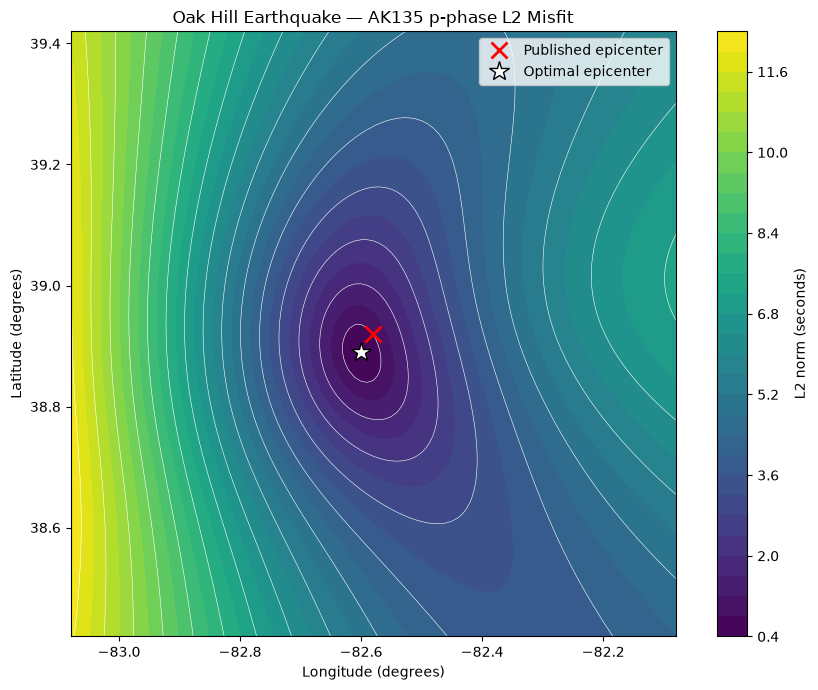

In [156]:
fig, ax = plt.subplots(figsize=(9, 7))

cf = ax.contourf(
    lons, lats, l2,
    levels=30, cmap="viridis"
)
fig.colorbar(cf, ax=ax, label="L2 norm (seconds)")

ax.contour(
    lons, lats, l2,
    levels=15, colors="white", linewidths=0.4
)

ax.plot(lon0, lat0, "rx", markersize=11,
        markeredgewidth=2, label="Published epicenter")
ax.plot(best_lon, best_lat, "w*", markersize=15,
        markeredgecolor="black", label="Optimal epicenter")

ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.set_title("Oak Hill Earthquake — AK135 p-phase L2 Misfit")
ax.legend()
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

### D.

####  For earthquake early warning, you need a few seconds of P wave data for 4 stations to determine an earthquake magnitude and origin time. For this earthquake and the 4 closest sites that you analyzed, assuming you need 3 seconds of P wave data, how many seconds of warning would we receive in Mendenhall Laboratory using taup theoretical ‘s’ travel times? Hint: the warning time will be the theoretical S-wave travel time minus the time at which the magnitude is computed, in this case 3 seconds after the P wave arrivals at the 4th station.

In [160]:
from obspy.geodetics.base import gps2dist_azimuth

eq_lat, eq_lon = 38.920, -82.581

stations = {
    "N4.Q51A": (39.026, -83.3456),
    "N4.Q52A": (38.9622, -82.2669),
    "OH.CHWO": (38.93602, -82.526105),
    "OH.CPOH": (38.8401, -83.5776),
    "OH.DSFO": (38.690952, -82.616898),
    "OH.SSF2": (38.6886, -83.1276),
}

distances = []

for name, (sta_lat, sta_lon) in stations.items():
    dist_m, _, _ = gps2dist_azimuth(
        eq_lat, eq_lon, sta_lat, sta_lon
    )
    distances.append((name, dist_m / 1000))

distances.sort(key=lambda x: x[1])

for name, dist_km in distances:
    print(f"{name}: {dist_km:.2f} km")

print("\nFour closest stations:")
for name, dist_km in distances[:4]:
    print(f"{name}: {dist_km:.2f} km")

OH.CHWO: 5.08 km
OH.DSFO: 25.62 km
N4.Q52A: 27.63 km
OH.SSF2: 53.98 km
N4.Q51A: 67.30 km
OH.CPOH: 86.93 km

Four closest stations:
OH.CHWO: 5.08 km
OH.DSFO: 25.62 km
N4.Q52A: 27.63 km
OH.SSF2: 53.98 km


In [152]:
from obspy.taup import TauPyModel
from obspy.geodetics.base import gps2dist_azimuth
import numpy as np

lat0, lon0 = 38.920, -82.581
depth_km = 25.9

lab_lat, lab_lon = 39.99842, -83.01112

distance_m, azimuth, back_azimuth = gps2dist_azimuth(
    lat0, lon0, lab_lat, lab_lon
)
distance_deg = distance_m / 1000 / 111.195

model = TauPyModel(model="ak135")
arrivals = model.get_travel_times(
    source_depth_in_km=depth_km,
    distance_in_degree=distance_deg,
    phase_list=["s"]
)

if not arrivals:
    raise ValueError("No theoretical 's' arrival found.")

s_time = arrivals[0].time

fourth_station_p_time = 9.05
data_requirement = 3.0

magnitude_ready = fourth_station_p_time + data_requirement
warning_time = s_time - magnitude_ready

print(f"Source-to-lab distance: {distance_deg:.3f} degrees")
print(f"Theoretical S-wave travel time: {s_time:.3f} s")
print(f"Magnitude ready after origin: {magnitude_ready:.3f} s")
print(f"Warning time: {warning_time:.3f} s")

Source-to-lab distance: 1.127 degrees
Theoretical S-wave travel time: 35.044 s
Magnitude ready after origin: 12.050 s
Warning time: 22.994 s


# All done!